<a href="https://colab.research.google.com/github/purinpurin11/Micas-blancas/blob/Diagrama-Ph---Suite-Piaxtla/Diagrama_micas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# ============================================================
# APFU de mica blanca normalizado a 11 oxígenos
# Archivo: Mica Blanca.xlsx
# ============================================================

import pandas as pd
import numpy as np
from google.colab import files

# 1) Subir archivo
print("Sube el archivo Mica Blanca.xlsx")
uploaded = files.upload()
filename = next(iter(uploaded))

# 2) Leer Excel
df = pd.read_excel(filename)
df.columns = [str(c).strip() for c in df.columns]

# Columnas de óxidos
oxide_cols = ['SiO2', 'TiO2', 'Al2O3', 'FeO', 'MnO', 'MgO', 'CaO', 'Na2O', 'K2O']

# Convertir a numérico y eliminar filas completamente vacías en óxidos
df[oxide_cols] = df[oxide_cols].apply(pd.to_numeric, errors='coerce')
df = df.dropna(subset=oxide_cols, how='all').reset_index(drop=True)
df[oxide_cols] = df[oxide_cols].fillna(0)

# 3) Crear identificador de muestra A2, A3, ..., A24
# La primera fila de datos del Excel corresponde a la fila 2
df.insert(0, 'Muestra', ['A' + str(i + 2) for i in range(len(df))])

# 4) Asignar grupo según el número de muestra
def asignar_grupo(muestra):
    n = int(muestra.replace('A', ''))
    if 2 <= n <= 5:
        return 'Metapelita de granate y cloritoide'
    elif 6 <= n <= 11:
        return 'Metapelita de granate'
    elif 12 <= n <= 18:
        return 'Veta félsica'
    elif 19 <= n <= 24:
        return 'Anfibolita de granate'
    else:
        return 'Otro'

df.insert(1, 'Grupo', df['Muestra'].apply(asignar_grupo))

# 5) Información de óxidos: peso molecular, cationes y oxígenos
oxide_info = {
    'SiO2':  {'MW': 60.0843,  'cat': {'Si': 1}, 'O': 2},
    'TiO2':  {'MW': 79.8658,  'cat': {'Ti': 1}, 'O': 2},
    'Al2O3': {'MW': 101.9613, 'cat': {'Al': 2}, 'O': 3},
    'FeO':   {'MW': 71.8444,  'cat': {'Fe': 1}, 'O': 1},  # Fe total como Fe2+
    'MnO':   {'MW': 70.9374,  'cat': {'Mn': 1}, 'O': 1},
    'MgO':   {'MW': 40.3044,  'cat': {'Mg': 1}, 'O': 1},
    'CaO':   {'MW': 56.0774,  'cat': {'Ca': 1}, 'O': 1},
    'Na2O':  {'MW': 61.9789,  'cat': {'Na': 2}, 'O': 1},
    'K2O':   {'MW': 94.1960,  'cat': {'K': 2},  'O': 1}
}

# 6) Calcular moles de óxidos y oxígenos
mol_ox = pd.DataFrame(index=df.index)
O_sum = pd.Series(0.0, index=df.index)

for ox, info in oxide_info.items():
    mol_ox[ox] = df[ox] / info['MW']
    O_sum += mol_ox[ox] * info['O']

# Factor de normalización a 11 oxígenos
factor = 11 / O_sum

# 7) Calcular APFU de cationes
cationes = ['Si', 'Ti', 'Al', 'Fe', 'Mn', 'Mg', 'Ca', 'Na', 'K']
apfu = pd.DataFrame(0.0, index=df.index, columns=cationes)

for ox, info in oxide_info.items():
    for cat, n_cat in info['cat'].items():
        apfu[cat] += mol_ox[ox] * n_cat * factor

apfu['Suma_cationes'] = apfu[cationes].sum(axis=1)
apfu['O_normalizado'] = O_sum * factor  # debe ser 11

# 8) Unir resultados
resultado = pd.concat([
    df[['Muestra', 'Grupo', 'Tipo de roca', 'Microstructura'] + oxide_cols],
    apfu
], axis=1)

# 9) Mostrar resultados
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

print("\nAPFU normalizado a 11 oxígenos:")
display(resultado.round(4))

# 10) Promedio por grupo
resumen = resultado.groupby('Grupo')[
    cationes + ['Suma_cationes']
].mean().round(4)

print("\nPromedio de APFU por grupo:")
display(resumen)

# 11) Guardar y descargar
resultado.to_csv('APFU_mica_blanca_11O.csv', index=False)
resultado.to_excel('APFU_mica_blanca_11O.xlsx', index=False)
resumen.to_csv('Resumen_APFU_por_grupo.csv')

files.download('APFU_mica_blanca_11O.csv')
files.download('APFU_mica_blanca_11O.xlsx')
files.download('Resumen_APFU_por_grupo.csv')

Sube el archivo Mica Blanca.xlsx


Saving Mica Blanca.xlsx to Mica Blanca.xlsx

APFU normalizado a 11 oxígenos:


,Muestra,Grupo,Tipo de roca,Microstructura,SiO2,TiO2,Al2O3,FeO,MnO,MgO,CaO,Na2O,K2O,Si,Ti,Al,Fe,Mn,Mg,Ca,Na,K,Suma_cationes,O_normalizado
0,A2,Metapelita de granate y cloritoide,Metapelita de granate y cloritoide,Matriz,47.505,0.243,29.947,1.054,0.024,3.837,0.009,1.238,8.760,3.2309,0.0124,2.4004,0.0600,0.0014,0.3890,0.0007,0.1632,0.7601,7.0181,11.0
1,A3,Metapelita de granate y cloritoide,Metapelita de granate y cloritoide,Matriz,49.028,0.252,30.495,1.055,0.000,4.298,0.008,0.993,8.681,3.2460,0.0126,2.3795,0.0584,0.0000,0.4242,0.0006,0.1275,0.7332,6.9820,11.0
2,A4,Metapelita de granate y cloritoide,Metapelita de granate y cloritoide,Matriz,48.109,0.232,29.863,1.019,0.021,3.486,0.008,1.400,8.599,3.2611,0.0118,2.3857,0.0578,0.0012,0.3523,0.0006,0.1840,0.7436,6.9980,11.0
3,A5,Metapelita de granate y cloritoide,Metapelita de granate y cloritoide,Matriz,45.912,0.186,30.493,0.990,0.000,2.676,0.008,1.298,8.544,3.2056,0.0098,2.5092,0.0578,0.0000,0.2785,0.0006,0.1757,0.7610,6.9984,11.0
4,A6,Metapelita de granate,Metapelita de granate,Matriz,44.931,0.283,30.081,1.614,0.000,4.726,0.000,1.050,9.328,3.1118,0.0147,2.4553,0.0935,0.0000,0.4879,0.0000,0.1410,0.8242,7.1284,11.0
5,A7,Metapelita de granate,Metapelita de granate,Matriz,45.800,0.245,30.387,1.660,0.002,4.758,0.009,1.182,9.530,3.1213,0.0126,2.4407,0.0946,0.0001,0.4834,0.0007,0.1562,0.8286,7.1381,11.0
6,A8,Metapelita de granate,Metapelita de granate,Matriz,47.368,0.286,30.103,1.595,0.008,5.367,0.016,1.217,9.042,3.1638,0.0144,2.3697,0.0891,0.0005,0.5344,0.0011,0.1576,0.7705,7.1010,11.0
7,A9,Metapelita de granate,Metapelita de granate,Matriz,46.887,0.285,29.628,1.467,0.022,4.415,0.000,1.099,9.366,3.1946,0.0146,2.3791,0.0836,0.0013,0.4484,0.0000,0.1452,0.8141,7.0809,11.0
8,A10,Metapelita de granate,Metapelita de granate,Matriz,45.240,0.231,29.599,1.825,0.013,5.350,0.013,1.102,9.119,3.1187,0.0120,2.4048,0.1052,0.0008,0.5498,0.0010,0.1473,0.8020,7.1415,11.0
9,A11,Metapelita de granate,Metapelita de granate,Matriz,44.045,0.241,30.934,1.419,0.000,4.447,0.000,1.215,9.293,3.0652,0.0126,2.5372,0.0826,0.0000,0.4614,0.0000,0.1639,0.8251,7.1480,11.0



Promedio de APFU por grupo:


,Si,Ti,Al,Fe,Mn,Mg,Ca,Na,K,Suma_cationes
Grupo,,,,,,,,,,
Anfibolita de granate,3.1560,0.0147,2.5416,0.1146,0.0014,0.2550,0.0008,0.0942,0.8546,7.0328
Metapelita de granate,3.1292,0.0135,2.4312,0.0914,0.0004,0.4942,0.0005,0.1519,0.8107,7.1230
Metapelita de granate y cloritoide,3.2359,0.0116,2.4187,0.0585,0.0006,0.3610,0.0006,0.1626,0.7495,6.9991
Veta félsica,3.1416,0.0121,2.5784,0.1212,0.0037,0.2416,0.0007,0.0873,0.8284,7.0150


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

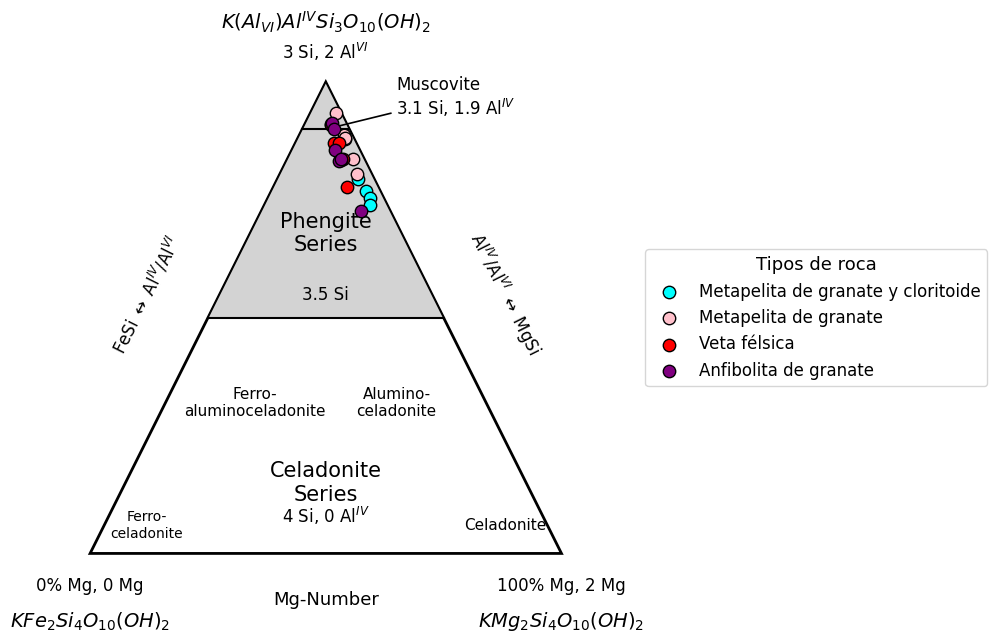

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import io

# ============================================================
# 1. Cargar los datos
# ============================================================
csv_data = """Muestra,Grupo,Tipo de roca,Microstructura,SiO2,TiO2,Al2O3,FeO,MnO,MgO,CaO,Na2O,K2O,Si,Ti,Al,Fe,Mn,Mg,Ca,Na,K,Suma_cationes,O_normalizado
A2,Metapelita de granate y cloritoide,Metapelita de granate y cloritoide,Matriz,47.505,0.243,29.947,1.054,0.024,3.837,0.009,1.238,8.76,3.230894135790013,0.01243339808493927,2.4004483496517257,0.05995040208121003,0.0013825485356950505,0.38903058870868323,0.0006558417372418351,0.16324924737567334,0.7600568060436779,7.018101318008859,11.0
A3,Metapelita de granate y cloritoide,Metapelita de granate y cloritoide,Matriz,49.028,0.252,30.495,1.055,0.0,4.298,0.008,0.993,8.681,3.2460262818600607,0.012551873531587677,2.3795351778595215,0.05841554027183814,0.0,0.4242118647611344,0.0005675066797410422,0.12746890066188954,0.7332231207675274,6.9820002663933,11.0
A4,Metapelita de granate y cloritoide,Metapelita de granate y cloritoide,Matriz,48.109,0.232,29.863,1.019,0.021,3.486,0.008,1.4,8.599,3.2610619129545406,0.011830983781409636,2.3857327164566304,0.05776635730845017,0.0012056958010887443,0.3522643086895065,0.0005810263625098622,0.18399579065381425,0.743599696709387,6.998038488717336,11.0
A5,Metapelita de granate y cloritoide,Metapelita de granate y cloritoide,Matriz,45.912,0.186,30.493,0.99,0.0,2.676,0.008,1.298,8.544,3.205633742375638,0.009770140134522928,2.509247385569369,0.05780840240705851,0.0,0.2785366472821493,0.0005984816131864605,0.1757152759820783,0.7610399746643802,6.9983500500283835,11.0
A6,Metapelita de granate,Metapelita de granate,Matriz,44.931,0.283,30.081,1.614,0.0,4.726,0.0,1.05,9.328,3.1117660035876806,0.014745090498826873,2.455323691712595,0.09348296131751145,0.0,0.4879362791949611,0.0,0.14099291310729356,0.8241531543839454,7.1284000938028145,11.0
A7,Metapelita de granate,Metapelita de granate,Matriz,45.8,0.245,30.387,1.66,0.002,4.758,0.009,1.182,9.53,3.1213241318676292,0.012561446008652135,2.4407137925371023,0.0946127277725004,0.00011544872125976316,0.48339969860045645,0.000657187111701246,0.15618452675410383,0.8285616597176296,7.138130619091035,11.0
A8,Metapelita de granate,Metapelita de granate,Matriz,47.368,0.286,30.103,1.595,0.008,5.367,0.016,1.217,9.042,3.1638064631976213,0.014371134486969054,2.369683130839479,0.08909506149767848,0.0004525854491540658,0.5343982185074385,0.0011450329380756465,0.15760230919183754,0.7704561107666703,7.101010046874924,11.0
A9,Metapelita de granate,Metapelita de granate,Matriz,46.887,0.285,29.628,1.467,0.022,4.415,0.0,1.099,9.366,3.1945758238327486,0.014608505028439793,2.379133039761066,0.08359089059137444,0.001269606609900435,0.4484355231316975,0.0,0.14517959635550026,0.8140919282506007,7.080884913561329,11.0
A10,Metapelita de granate,Metapelita de granate,Matriz,45.24,0.231,29.599,1.825,0.013,5.35,0.013,1.102,9.119,3.118706926099281,0.011980201095283858,2.404831459873834,0.10521627469042537,0.0007590686585273996,0.5498121034641862,0.0009602149360958524,0.14729252269669083,0.8019692654050754,7.141528036919399,11.0
A11,Metapelita de granate,Metapelita de granate,Matriz,44.045,0.241,30.934,1.419,0.0,4.447,0.0,1.215,9.293,3.065237555832066,0.012617831568287117,2.5372265210101395,0.08258820037856655,0.0,0.4613634634455186,0.0,0.16394226804449474,0.8250532916755045,7.148029131954577,11.0
A12,Veta félsica,Veta félsica,Matriz,48.729,0.467,31.446,2.089,0.19,2.712,0.0,0.689,9.383,3.222108008321987,0.023231092575520123,2.4506068484728356,0.11552051569793731,0.010641232580478315,0.2673319252346999,0.0,0.08833218118891174,0.7915035227763213,6.969275326848692,11.0
A13,Veta félsica,Veta félsica,Matriz,47.958,0.227,33.545,1.246,0.0,1.853,0.0,0.814,10.344,3.1636101451866128,0.011265433623764998,2.607986445616549,0.06873976170352179,0.0,0.18222411979173012,0.0,0.10411023781896797,0.8705003470993712,7.008436490840517,11.0
A14,Veta félsica,Veta félsica,Matriz,45.56,0.252,34.065,1.585,0.0,1.446,0.0,0.7,9.726,3.091960713977497,0.012866219379091395,2.724672337483453,0.08995961788536967,0.0,0.1462941939155406,0.0,0.09210759214351241,0.8420600383779513,6.999920713162417,11.0
A15,Veta félsica,Veta félsica,Matriz,46.605,0.294,33.874,1.727,0.076,1.64,0.019,0.627,8.983,3.1288377715133753,0.014849027909319678,2.6802336423789384,0.09696409642371911,0.0043216527214984405,0.16413565292344942,0.0013667128280110325,0.08161410299536434,0.7693615423836829,6.941684202077358,10.999999999999998
A16,Veta félsica,Veta félsica,Matriz,46.774,0.163,32.008,1.869,0.0,2.329,0.0,0.628,10.173,3.1660131363940183,0.008300341582828863,2.5534207132341455,0.10579998016238046,0.0,0.23500994198114705,0.0,0.08241665467123419,0.8784474494318846,7.0294082174576396,11.0
A17,Veta félsica,Veta félsica,Matriz,44.378,0.149,29.136,5.047,0.114,4.905,0.045,0.531,8.415,3.088656119479448,0.007801682287748808,2.3899422023341717,0.29376714376616797,0.006720358215001411,0.5089198489003781,0.0033557336460586598,0.07165450345098673,0.7471615134224937,7.117979105502454,11.0
A18,Veta félsica,Veta félsica,Matriz,46.862,0.121,33.559,1.386,0.076,1.883,0.0,0.704,10.561,3.1301448003581425,0.006080357835192142,2.6418506200728267,0.07742387841202017,0.004299747377350716,0.18750051906251528,0.0,0.09117240380137834,0.899926813503031,7.038399140422457,11.0
A19,Anfibolita de granate,Anfibolita de granate,Manto,45.9,0.259,33.514,2.036,0.0,2.102,0.022,0.969,9.931,3.086723058871315,0.013103427328349496,2.6562373770668373,0.11450668400023654,0.0,0.2107299373280609,0.001585188079680968,0.1263443702950769,0.851993934889794,7.061223977859352,11.000000000000002
A20,Anfibolita de granate,Anfibolita de granate,Manto,46.885,0.446,32.19,2.291,0.152,2.278,0.032,1.077,9.589,3.1450345106209343,0.022507461364748963,2.544884690870375,0.12852412856510625,0.008636162831024497,0.22780002127286353,0.0022999299547430676,0.1400729695221935,0.8205845846764727,7.040344459678463,11.0
A21,Anfibolita de granate,Anfibolita de granate,Manto,46.917,0.512,31.85,2.038,0.0,2.315,0.0,0.975,9.219,3.168281515915738,0.026011395339868116,2.534886995698085,0.11509747405262713,0.0,0.2330521265745388,0.0,0.1276571905599166,0.7942109760690673,6.9991976742098405,11.0
A22,Anfibolita de granate,Anfibolita de granate,Matriz,48.469,0.103,29.282,1.981,0.0,3.785,0.008,0.087,10.374,3.2735504609362955,0.005233501640119222,2.3308340511080834,0.11189419070711884,0.0,0.38109162939219604,0.0005789194003245845,0.011392561201631847,0.8938399561691831,7.008415270554952,11.0
A23,Anfibolita de granate,Anfibolita de granate,Matriz,45.611,0.247,32.931,1.924,0.0,2.198,0.0,0.711,10.233,3.0987033848740486,0.012624306364382389,2.6367622290593444,0.10931595769615027,0.0,0.22261101311185913,0.0,0.09365417675351158,0.8868944294987137,7.06056549735801,11.0
A24,Anfibolita de granate,Anfibolita de granate,Matriz,46.491,0.168,31.745,1.897,0.0,2.508,0.008,0.499,10.135,3.163870858602584,0.00860120506409518,2.5461314976493843,0.10796556832286827,0.0,0.2544403230563176,0.0005833282157535094,0.06584117059742035,0.8798976425978315,7.027331594106255,11.000000000000002
"""

df = pd.read_csv(io.StringIO(csv_data))
df['Mg_number'] = df['Mg'] / (df['Mg'] + df['Fe'])

# ============================================================
# 2. Función para calcular coordenadas
# ============================================================
def calc_xy(Si, Mg_number):
    y = 4.0 - Si
    x = 0.5 * y + Mg_number * (1.0 - y)
    return x, y

# ============================================================
# 3. Configuración de la figura
# ============================================================
fig, ax = plt.subplots(figsize=(10, 11))
ax.set_aspect('equal')
ax.axis('off')

# Vértices del triángulo principal
vertices = [(0, 0), (1, 0), (0.5, 1), (0, 0)]
triangle = patches.Polygon(vertices, closed=True, edgecolor='black', facecolor='none', lw=2)
ax.add_patch(triangle)

# Líneas de límites
y_31 = 4.0 - 3.1
y_35 = 4.0 - 3.5
x_31_izq, _ = calc_xy(3.1, 0)
x_31_der, _ = calc_xy(3.1, 1)
x_35_izq, _ = calc_xy(3.5, 0)
x_35_der, _ = calc_xy(3.5, 1)

ax.plot([x_31_izq, x_31_der], [y_31, y_31], 'k-', lw=1.5)
ax.plot([x_35_izq, x_35_der], [y_35, y_35], 'k-', lw=1.5)

# Rellenos grises
musc_vertices = [(x_31_izq, y_31), (x_31_der, y_31), (0.5, 1)]
ax.add_patch(patches.Polygon(musc_vertices, closed=True, facecolor='lightgray', edgecolor='black', lw=1))

feng_vertices = [(x_31_izq, y_31), (x_31_der, y_31), (x_35_der, y_35), (x_35_izq, y_35)]
ax.add_patch(patches.Polygon(feng_vertices, closed=True, facecolor='lightgray', edgecolor='black', lw=1))

# ============================================================
# 4. Etiquetas del diagrama
# ============================================================
# Fórmula superior
ax.text(0.5, 1.10, r"$K(Al_{VI})Al^{IV}Si_3O_{10}(OH)_2$", ha='center', va='bottom', fontsize=14)
ax.text(0.5, 1.04, r"3 Si, 2 Al$^{VI}$", ha='center', va='bottom', fontsize=12)

# Anotación Muscovita
ax.annotate("Muscovite\n3.1 Si, 1.9 Al$^{IV}$", xy=(0.5, y_31), xytext=(0.65, 0.93),
            arrowprops=dict(arrowstyle="->", lw=1.2), fontsize=12, ha='left')

# Zona Fengita
ax.text(0.5, 0.68, "Phengite\nSeries", ha='center', va='center', fontsize=15)
ax.text(0.5, y_35 + 0.03, "3.5 Si", ha='center', va='bottom', fontsize=12)

# Zonas inferiores (Celadonitas)
ax.text(0.35, 0.32, "Ferro-\naluminoceladonite", ha='center', va='center', fontsize=11)
ax.text(0.65, 0.32, "Alumino-\nceladonite", ha='center', va='center', fontsize=11)
ax.text(0.5, 0.15, "Celadonite\nSeries", ha='center', va='center', fontsize=15)
ax.text(0.5, 0.08, "4 Si, 0 Al$^{IV}$", ha='center', va='center', fontsize=12)

ax.text(0.12, 0.06, "Ferro-\nceladonite", ha='center', va='center', fontsize=10)
ax.text(0.88, 0.06, "Celadonite", ha='center', va='center', fontsize=11)

# Ejes y fórmulas inferiores
ax.text(0.5, -0.08, "Mg-Number", ha='center', va='top', fontsize=13)
ax.text(0.0, -0.05, "0% Mg, 0 Mg", ha='center', va='top', fontsize=12)
ax.text(0.0, -0.12, r"$KFe_2Si_4O_{10}(OH)_2$", ha='center', va='top', fontsize=14)
ax.text(1.0, -0.05, "100% Mg, 2 Mg", ha='center', va='top', fontsize=12)
ax.text(1.0, -0.12, r"$KMg_2Si_4O_{10}(OH)_2$", ha='center', va='top', fontsize=14)

# Flechas laterales
ax.text(0.12, 0.55, r"FeSi $\leftrightarrow$ Al$^{IV}$/Al$^{VI}$", rotation=63.4, ha='center', va='center', fontsize=12)
ax.text(0.88, 0.55, r"Al$^{IV}$/Al$^{VI}$ $\leftrightarrow$ MgSi", rotation=-63.4, ha='center', va='center', fontsize=12)

# ============================================================
# 5. Graficar muestras (TODOS CÍRCULOS CON NUEVOS COLORES)
# ============================================================
grupos_estilos = {
    'Metapelita de granate y cloritoide': {'color': 'cyan', 'marker': 'o', 'label': 'Metapelita de granate y cloritoide'},
    'Metapelita de granate': {'color': 'pink', 'marker': 'o', 'label': 'Metapelita de granate'},
    'Veta félsica': {'color': 'red', 'marker': 'o', 'label': 'Veta félsica'},
    'Anfibolita de granate': {'color': 'purple', 'marker': 'o', 'label': 'Anfibolita de granate'}
}

for grupo, estilo in grupos_estilos.items():
    subset = df[df['Grupo'] == grupo]
    x_vals, y_vals = [], []

    for _, row in subset.iterrows():
        si = row['Si']
        mg_num = row['Mg_number']
        x, y = calc_xy(si, mg_num)
        x_vals.append(x)
        y_vals.append(y)

    # Solo graficamos los puntos, sin agregar texto
    ax.scatter(x_vals, y_vals, color=estilo['color'], marker=estilo['marker'],
               s=80, edgecolor='black', zorder=5, label=estilo['label'])

# Leyenda
ax.legend(loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize=12, title="Tipos de roca", title_fontsize=13)

# Ajustar límites
ax.set_xlim(-0.1, 1.1)
ax.set_ylim(-0.15, 1.15)

plt.tight_layout()
plt.show()